# Session 4 — Encoder, decoder, encoder–decoder

Sessions 1 to 3 built and trained a decoder: every token reads only the tokens before it, and the model is trained to predict the next one. GPT-2 is such a model. It is one of three layouts that the same attention-and-MLP block supports. This session runs a real model of each kind on the same sentence: BERT (an encoder), GPT-2 (a decoder) and T5 (an encoder–decoder), and measures what the layout and the training objective change.

**By the end of the session you should be able to:**

1. say which tokens each of the three layouts can read, and show it from a real model's attention;
2. explain why a masked-token objective can use the words after a blank and a next-token objective cannot, and what the masking recipe does;
3. read cross-attention in an encoder–decoder model as an alignment between source and output.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `torch` and `transformers`, and the GPT-2 download from Session 0. The first run also downloads BERT-base (about 440 MB) and T5-small (about 240 MB). The outputs are already saved in the notebook. It takes about a minute on a GPU. Section 3 reads the TinyStories shard downloaded in Session 3.

In [1]:
import glob, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from aij_common import DEVICE, set_seed, load_gpt2
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM, AutoModelForSeq2SeqLM
from transformers.utils import logging
logging.set_verbosity_error(); set_seed(0)
bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased"); bert = AutoModelForMaskedLM.from_pretrained("bert-base-uncased", attn_implementation="eager").eval().to(DEVICE)
gpt_tok, gpt = load_gpt2(attn="eager")
t5_tok = AutoTokenizer.from_pretrained("t5-small"); t5 = AutoModelForSeq2SeqLM.from_pretrained("t5-small", attn_implementation="eager").eval().to(DEVICE)
params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"BERT-base {params(bert):.0f}M parameters, GPT-2 small {params(gpt):.0f}M, T5-small {params(t5):.0f}M")

BERT-base 110M parameters, GPT-2 small 124M, T5-small 61M


The next cell holds three small helpers: BERT's probabilities for a blank, the top words from them, and the total log probability GPT-2 gives to a text. Presenters skip it on screen.

In [2]:
@torch.no_grad()
def bert_fill(text):
    """Probabilities BERT gives to every vocabulary word at the [MASK] position."""
    enc = bert_tok(text, return_tensors="pt").to(DEVICE); pos = (enc.input_ids[0] == bert_tok.mask_token_id).nonzero()[0].item()
    return bert(**enc).logits[0, pos].softmax(-1).cpu()

def top_words(p, k=5): return [(bert_tok.decode(i), round(v.item(), 3)) for v, i in zip(*p.topk(k))]

@torch.no_grad()
def gpt_logprob(text):
    """Total log probability GPT-2 gives to a text (with <|endoftext|> in front)."""
    ids = torch.tensor([[gpt_tok.eos_token_id] + gpt_tok(text).input_ids], device=DEVICE)
    return gpt(ids).logits[0, :-1].float().log_softmax(-1).gather(1, ids[0, 1:, None]).sum().item()

## 1. What each layout can read

All three layouts use the block from Session 2. They differ in the mask. An **encoder** (BERT) has no mask: every token can read every other token, before and after. A **decoder** (GPT-2) has the causal mask: a token reads only itself and earlier tokens. An **encoder–decoder** (T5) does both: an encoder reads the source text without a mask, and a decoder reads the output so far with the causal mask, plus the whole encoded source through **cross-attention**.

We measure the first two on the sentence from Session 1. For each layer we add up the attention weight that points at later tokens.

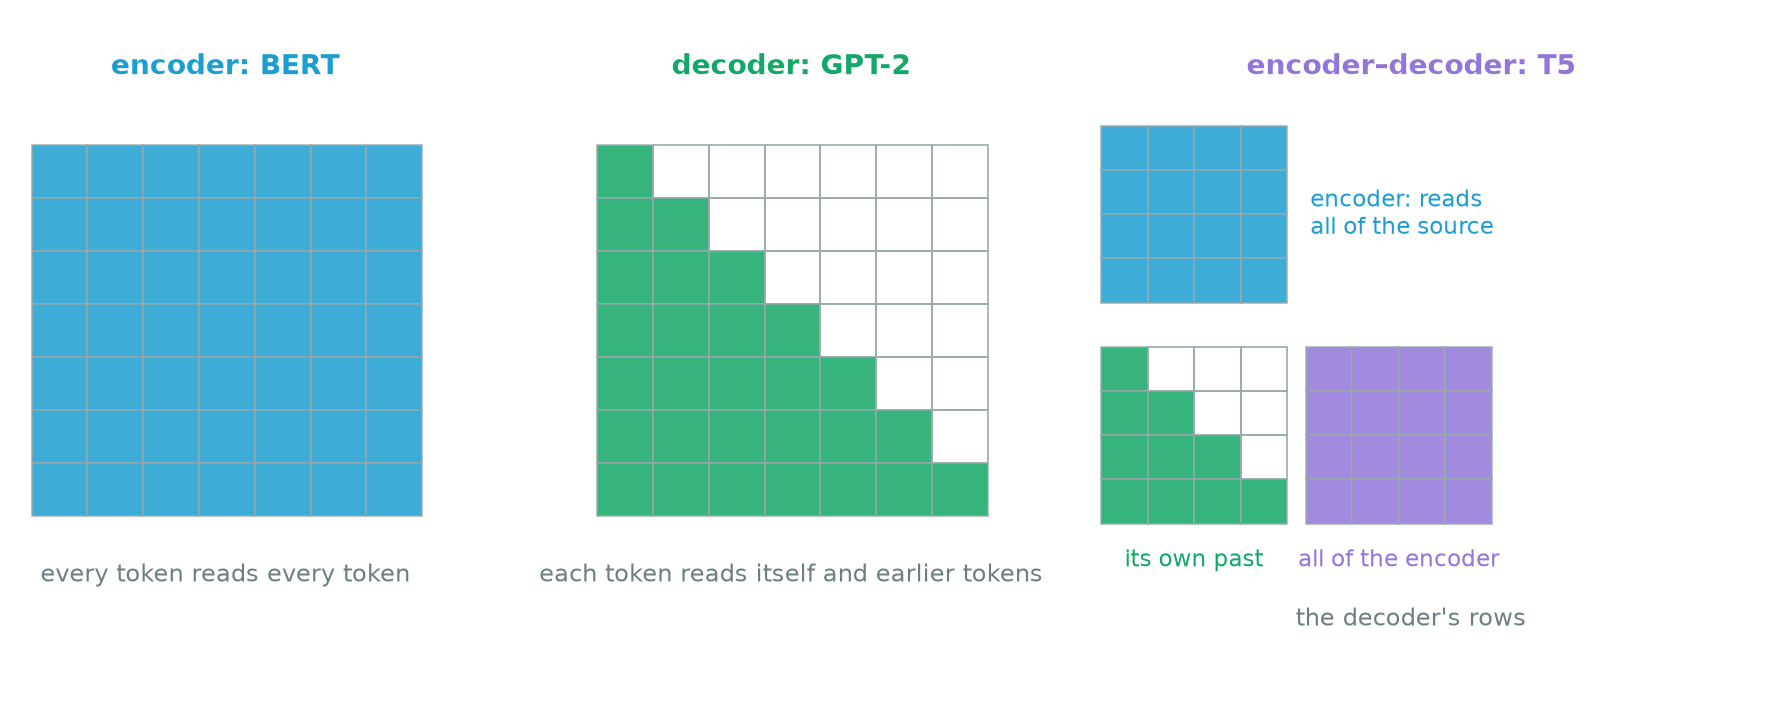

*Figure 4.1 — The three layouts drawn as masks. Row i shows what token i can read. An encoder reads everything, a decoder reads itself and what came before, and an encoder–decoder has an encoder that reads everything plus a decoder that reads its own past and, through cross-attention, all of the encoder's output.*

In [3]:
sentence = "The robot placed the battery beside the charger because it was empty."
with torch.no_grad():
    b_att = torch.stack(bert.bert(**bert_tok(sentence, return_tensors="pt").to(DEVICE), output_attentions=True).attentions)[:, 0].cpu()
    g_ids = torch.tensor([[gpt_tok.eos_token_id] + gpt_tok(sentence).input_ids], device=DEVICE)
    g_att = torch.stack(gpt(g_ids, output_attentions=True).attentions)[:, 0].cpu()
def future_mass(att):
    T = att.shape[-1]; return (att * torch.triu(torch.ones(T, T), 1)).sum(-1).mean((1, 2))      # attention weight that points at later tokens, per layer
print("share of attention that points at LATER tokens, by layer")
print("BERT :", [round(x, 2) for x in future_mass(b_att).tolist()], f" mean {future_mass(b_att).mean():.2f}")
print("GPT-2:", [round(x, 2) for x in future_mass(g_att).tolist()], f" mean {future_mass(g_att).mean():.2f}")

share of attention that points at LATER tokens, by layer
BERT : [0.38, 0.32, 0.41, 0.42, 0.67, 0.74, 0.66, 0.71, 0.69, 0.67, 0.68, 0.69]  mean 0.59
GPT-2: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  mean 0.00


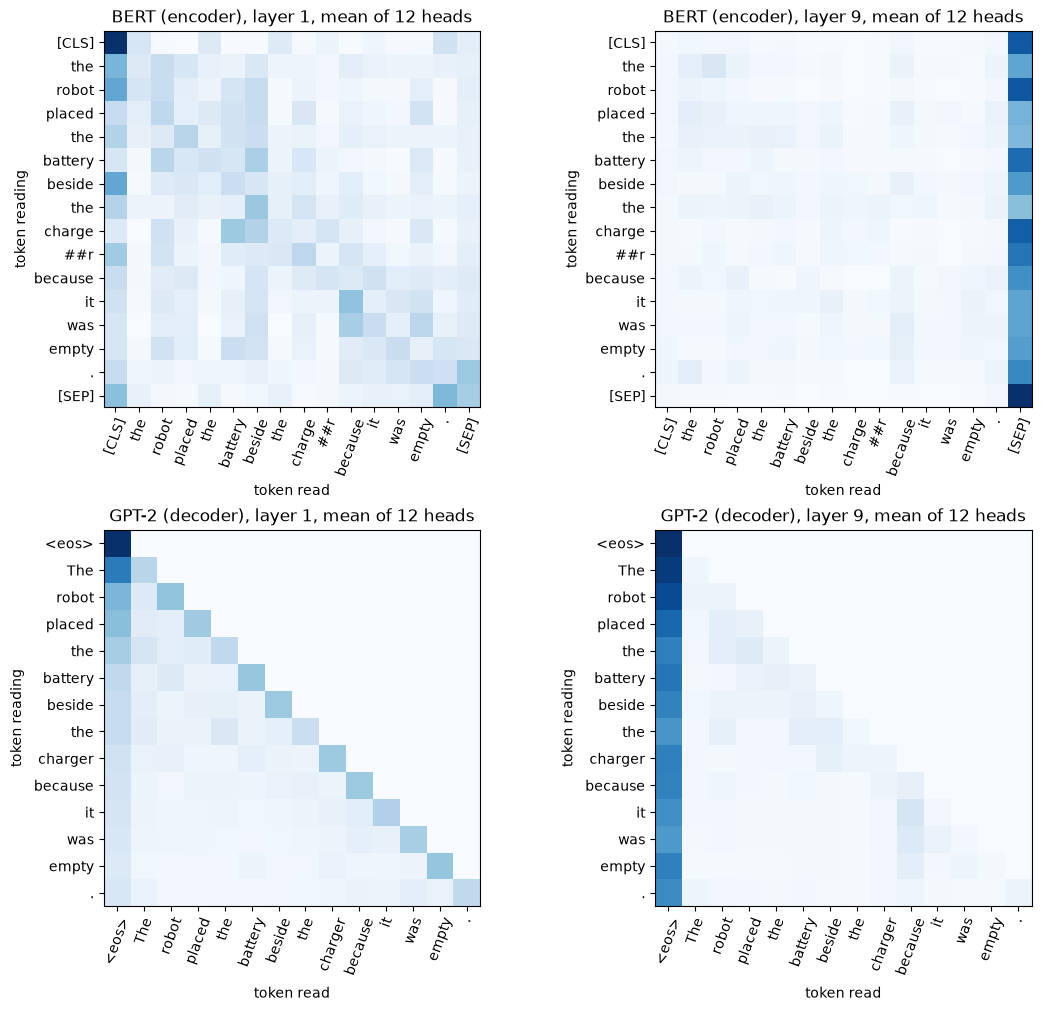

In [4]:
b_toks = bert_tok.convert_ids_to_tokens(bert_tok(sentence).input_ids); g_toks = ["<eos>"] + [gpt_tok.decode(i) for i in gpt_tok(sentence).input_ids]
fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for row, (att, toks, name) in enumerate([(b_att, b_toks, "BERT (encoder)"), (g_att, g_toks, "GPT-2 (decoder)")]):
    for col, layer in enumerate((0, 8)):
        ax = axes[row, col]; ax.imshow(att[layer].mean(0), cmap="Blues"); ax.set_xticks(range(len(toks)), toks, rotation=70); ax.set_yticks(range(len(toks)), toks)
        ax.set(title=f"{name}, layer {layer + 1}, mean of 12 heads", xlabel="token read", ylabel="token reading")
plt.show()

In GPT-2 the share is exactly 0 in every layer, which is the mask. In BERT, an average of 0.59 of the attention weight points at later tokens, from 0.32 in layer 2 to 0.74 in layer 6. BERT really does use the words that follow.

The figure shows attention averaged over the 12 heads, in layers 1 and 9. In layer 1 BERT's map is a full square: each token spreads its attention over the whole sentence, with some of it on `[CLS]`. GPT-2's map is a lower triangle, with weight on the token itself and the first token. By layer 9, both models have collapsed to a single column: BERT sends most attention to the final `[SEP]` token and GPT-2 to the first token. These are the attention sinks from Session 1, and they show that the pattern of attention in a middle layer is a poor guide to what a model reads.

## 2. What the objective lets a model use

The layout decides what a token can read, and the objective decides what the model is trained to do with it. BERT's objective is to recover tokens that have been hidden, using both sides. We give it the blank in *The battery is [MASK], so the robot stopped working.*, then cut the sentence off after the blank.

> **Pause:** with the second half of the sentence available, which word will BERT put in the blank? Will its answer be the same without the second half?
>
> - **A.** `empty`, both times.
> - **B.** `dead` with the second half, and a different word without it.
> - **C.** `dead`, both times.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** With the whole sentence BERT puts 0.419 on `dead`. With the sentence cut off after the blank, `dead` falls to 0.041 and `charged` leads with 0.055.

</details>

In [5]:
blank = "The battery is [MASK], so the robot stopped working."
p_both, p_left = bert_fill(blank), bert_fill("The battery is [MASK].")
print("with the rest of the sentence :", top_words(p_both)); print("sentence ends after the blank:", top_words(p_left))

with the rest of the sentence : [('dead', 0.419), ('depleted', 0.038), ('out', 0.037), ('gone', 0.035), ('failing', 0.024)]
sentence ends after the blank: [('charged', 0.055), ('dead', 0.041), ('free', 0.036), ('empty', 0.031), ('unused', 0.023)]


With the whole sentence, BERT puts 0.419 on `dead`, and no other word above 0.04. With the sentence ending after the blank, `dead` falls to 0.041, and the top word is `charged` with 0.055. The right-hand half of the sentence decides the answer.

A decoder cannot condition on that half when choosing the word, because the word comes before it. It can still be used to fill in a blank, by scoring complete sentences: put each candidate in the blank and ask how probable the whole sentence is. The cell compares the options on five candidates, with each model's scores rescaled to add up to 1 over the candidates.

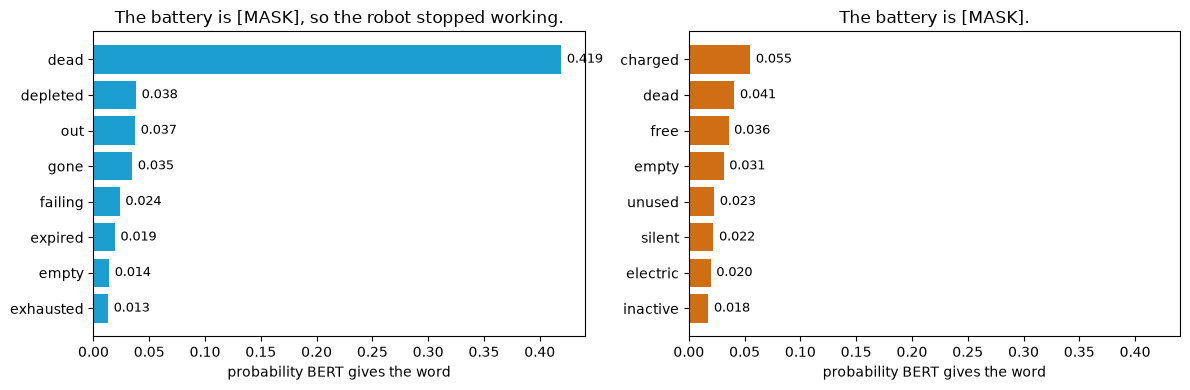

with the right half: [('dead', 0.419), ('depleted', 0.038), ('out', 0.037)]  without it: [('charged', 0.055), ('dead', 0.041), ('free', 0.036)]  probability of 'dead' without: 0.041


In [6]:
# Figure 4.2: BERT's top words for the blank, with and without the right-hand half of the sentence
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, (p, title, color) in zip(axes, [(p_both, "The battery is [MASK], so the robot stopped working.", "#1C9FD0"), (p_left, "The battery is [MASK].", "#CF6E14")]):
    top = p.topk(8)
    ax.barh(range(8), top.values.numpy(), color=color); ax.invert_yaxis()
    ax.set(yticks=range(8), yticklabels=[bert_tok.decode(i) for i in top.indices], xlabel="probability BERT gives the word", title=title)
    for k, v in enumerate(top.values): ax.text(v + 0.005, k, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()
print("with the right half:", top_words(p_both, 3), " without it:", top_words(p_left, 3), f" probability of 'dead' without: {p_left[bert_tok.convert_tokens_to_ids('dead')]:.3f}")

*Figure 4.2 — BERT's probabilities for the blank, with and without the second half of the sentence. With "…, so the robot stopped working" after the blank (left), `dead` takes 0.419 and the next words are far behind. With the sentence ending at the blank (right), the probability is spread over several plausible words and `dead` falls to 0.041.*

In [7]:
cands = ["dead", "empty", "low", "full", "charged"]
sentence_scores = np.array([gpt_logprob(f"The battery is {w}, so the robot stopped working.") for w in cands])
with torch.no_grad():
    ids = torch.tensor([[gpt_tok.eos_token_id] + gpt_tok("The battery is").input_ids], device=DEVICE); lp = gpt(ids).logits[0, -1].float().log_softmax(-1).cpu()
next_word = np.array([lp[gpt_tok(" " + w).input_ids[0]].item() for w in cands])
norm = lambda v: np.exp(v - v.max()) / np.exp(v - v.max()).sum()
bert_ids = [bert_tok.convert_tokens_to_ids(w) for w in cands]
display(pd.DataFrame({"BERT, blank with right context": norm(np.log(p_both[bert_ids].numpy())), "BERT, no right context": norm(np.log(p_left[bert_ids].numpy())),
                      "GPT-2, next word after 'The battery is'": norm(next_word), "GPT-2, scores the whole sentence for each word": norm(sentence_scores)}, index=cands).round(2))

,"BERT, blank with right context","BERT, no right context","GPT-2, next word after 'The battery is'","GPT-2, scores the whole sentence for each word"
dead,0.92,0.29,0.11,0.82
empty,0.03,0.22,0.02,0.16
low,0.03,0.03,0.05,0.01
full,0.01,0.06,0.07,0.01
charged,0.01,0.39,0.74,0.00


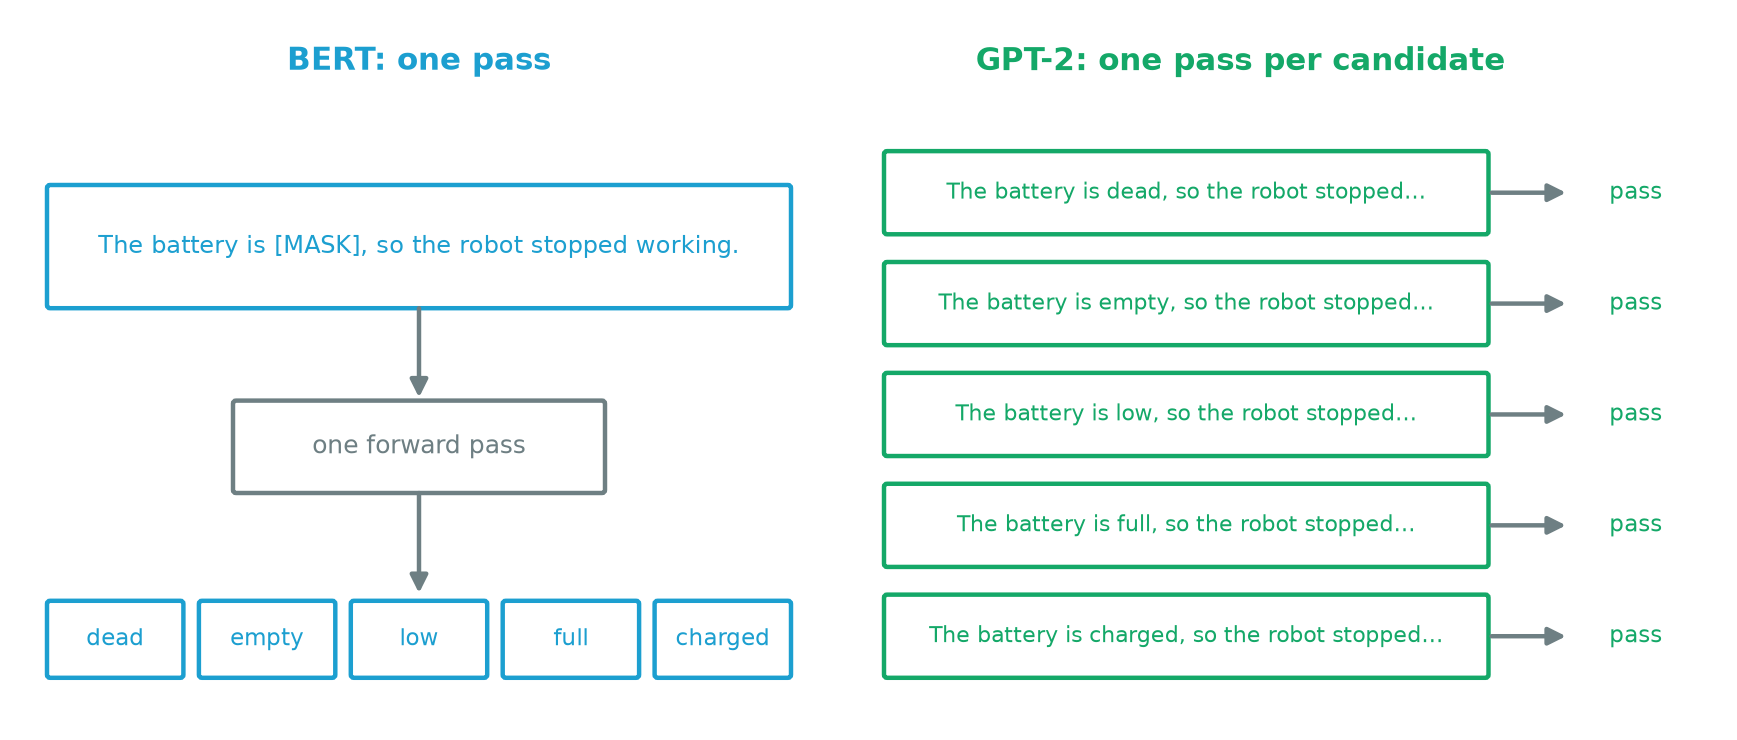

*Figure 4.3 — Using the right-hand context to fill a blank. BERT reads the sentence with one [MASK] and gives a probability to every candidate word in one pass. GPT-2 has to score a complete sentence for each candidate, so it needs one pass per candidate.*

BERT with the right context gives `dead` 0.92. Without it, BERT is unsure (`charged` 0.39, `dead` 0.29, `empty` 0.22). GPT-2 asked for the next word after *The battery is* strongly prefers `charged` (0.74), the same top choice as BERT without the right context. But when GPT-2 scores the whole sentence for each candidate, it agrees with BERT: `dead` 0.82 and `empty` 0.16.

So a decoder can use the later words, but it needs a full forward pass for each candidate (5 here), while BERT needs one pass for all words. This is the practical meaning of the layout: the encoder gets bidirectional context in one pass, and the decoder gets generation in one pass.

## 3. How BERT is taught to fill blanks

BERT's recipe chooses 15% of the tokens as targets. Of those, 80% are replaced by `[MASK]`, 10% by a random token and 10% are left unchanged. The model must predict the original token at every chosen position. Replacing only with `[MASK]` would teach a model that never sees `[MASK]` in real use. Random and unchanged tokens force it to look at every position and ask whether the token is right.

We apply the recipe to 600 held-out TinyStories stories, and check BERT on its own training task.

> **Pause:** BERT's top guess is judged against the original token. Which of the three treatments will it get right most often?
>
> - **A.** The masked tokens.
> - **B.** The tokens left unchanged.
> - **C.** The tokens replaced by a random word.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** Tokens left unchanged are recovered 0.993 of the time, masked tokens 0.704 and randomised tokens 0.549.

</details>

In [8]:
txt = pd.read_parquet(glob.glob(os.path.expanduser("~/.cache/huggingface/hub/datasets--roneneldan--TinyStories/snapshots/*/data/train-00000*.parquet"))[0]).text.tolist()[-2000:]
g, rows = torch.Generator().manual_seed(0), []
for story in txt[:600]:
    ids = bert_tok(story, truncation=True, max_length=128, return_tensors="pt").input_ids[0]
    chosen = torch.arange(1, len(ids) - 1)[torch.rand(len(ids) - 2, generator=g) < 0.15]          # 15% of the real tokens
    if len(chosen) == 0: continue
    draw, corrupted = torch.rand(len(chosen), generator=g), ids.clone()
    for pos, u in zip(chosen, draw):
        if u < 0.8: corrupted[pos] = bert_tok.mask_token_id                                         # 80%: replace by [MASK]
        elif u < 0.9: corrupted[pos] = torch.randint(1000, bert_tok.vocab_size, (1,), generator=g).item()    # 10%: random word
    with torch.no_grad(): guess = bert(corrupted[None].to(DEVICE)).logits[0].argmax(-1).cpu()
    rows += [("[MASK]" if u < 0.8 else "random word" if u < 0.9 else "left unchanged", int(guess[p] == ids[p])) for p, u in zip(chosen, draw)]
mlm = pd.DataFrame(rows, columns=["treatment", "correct"])
display(mlm.groupby("treatment").correct.agg(["count", "mean"]).rename(columns={"count": "tokens", "mean": "BERT recovers the original"}).round(3))
print(f"{len(mlm):,} masked positions in {len(txt[:600])} held-out stories; overall accuracy {mlm.correct.mean():.3f}")

,tokens,BERT recovers the original
treatment,,
[MASK],8995,0.704
left unchanged,1120,0.993
random word,1112,0.549


11,227 masked positions in 600 held-out stories; overall accuracy 0.717


Of 11,227 chosen positions, 80% were masked, 10% randomised and 10% left unchanged, as the recipe says. BERT recovers 70.4% of the masked tokens. For tokens left unchanged it is right 99.3% of the time, because the answer is in front of it. For tokens replaced by a random word it is right 54.9% of the time, so it often puts back the original even when a different word is there. The overall accuracy is 71.7%. These stories are simple, so the accuracies are higher than they would be on harder text.

## 4. Reading and writing: an encoder–decoder

T5 treats every task as text in, text out. We give T5-small an instruction followed by the English sentence, and it writes the French. Cross-attention lets each output token read the encoded source. We take the attention weights from the decoder's cross-attention layers, averaged over the 8 heads, and compare them with an alignment that we wrote by hand: which English word each French token corresponds to.

> **Pause:** *vide* is the French word for *empty*. Which English token should its cross-attention point at?
>
> - **A.** `The`.
> - **B.** `battery`.
> - **C.** `empty`.
> - **D.** `stopped`.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** The hand-written alignment pairs `vide` with `empty`. In the second decoder layer all 12 French tokens put their strongest cross-attention on the English word we paired them with.

</details>

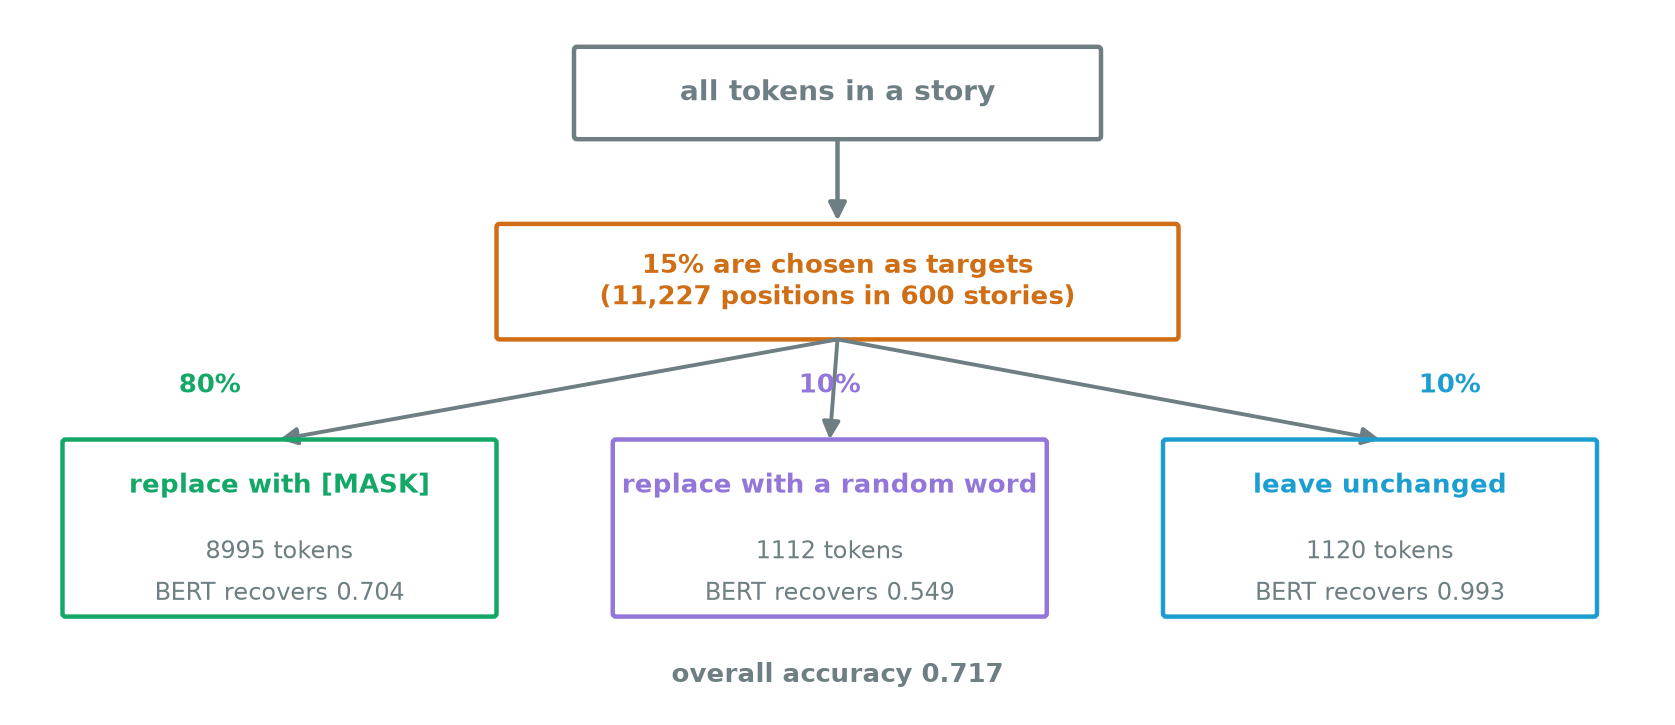

*Figure 4.4 — BERT's masking recipe with what was measured on each branch. Of 11,227 chosen positions, 8995 were masked and BERT recovered 0.704 of them; 1112 were replaced by a random word and BERT recovered 0.549; 1120 were left unchanged and BERT recovered 0.993. The overall accuracy was 0.717.*

In [9]:
source = "translate English to French: The battery is empty, so the robot stopped working."
enc = t5_tok(source, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    out = t5.generate(**enc, max_new_tokens=40, num_beams=1)
    cross = torch.stack(t5(**enc, decoder_input_ids=out, output_attentions=True).cross_attentions)[:, 0].mean(1).cpu()      # (layers, decoder positions, source positions), averaged over heads
src_tok, dec_tok = t5_tok.convert_ids_to_tokens(enc.input_ids[0]), t5_tok.convert_ids_to_tokens(out[0])
print(t5_tok.decode(out[0], skip_special_tokens=True)); print("decoder tokens:", dec_tok); print("shape of the cross-attention:", tuple(cross.shape), "(layers, decoder tokens, source tokens)")

La batterie est vide, donc le robot cesse de fonctionner.
decoder tokens: ['<pad>', '▁La', '▁', 'batterie', '▁est', '▁vide', ',', '▁donc', '▁le', '▁robot', '▁cesse', '▁de', '▁fonctionne', 'r', '.', '</s>']
shape of the cross-attention: (6, 16, 17) (layers, decoder tokens, source tokens)


hand-written alignment: {'▁La': '▁The', 'batterie': '▁battery', '▁est': '▁is', '▁vide': '▁empty', ',': ',', '▁donc': '▁so', '▁le': '▁the', '▁robot': '▁robot', '▁cesse': '▁stopped', '▁fonctionne': '▁working', 'r': '▁working', '.': '.'}
decoder layer 1..6: tokens whose strongest cross-attention matches the hand-written alignment (of 12): [8, 12, 6, 0, 0, 0]


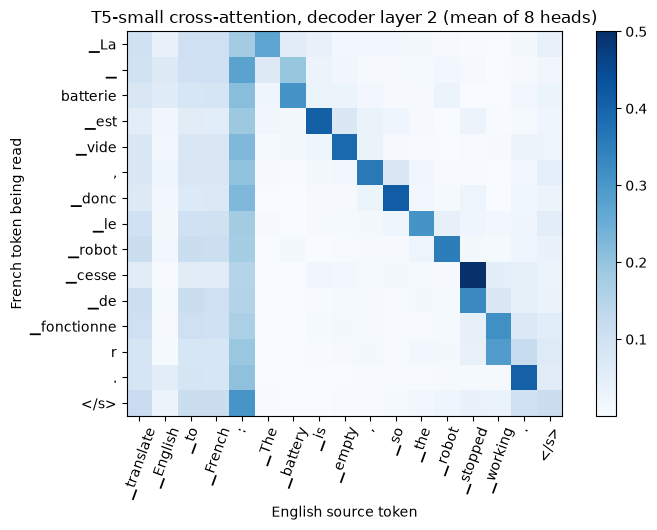

In [10]:
reference = {1: 5, 3: 6, 4: 7, 5: 8, 6: 9, 7: 10, 8: 11, 9: 12, 10: 13, 12: 14, 13: 14, 14: 15}      # decoder token read -> English token it corresponds to (written by hand)
print("hand-written alignment:", {dec_tok[r]: src_tok[s] for r, s in reference.items()})
hits = [sum(int(cross[l, r].argmax()) == s for r, s in reference.items()) for l in range(cross.shape[0])]
print("decoder layer 1..6: tokens whose strongest cross-attention matches the hand-written alignment (of 12):", hits)
fig, ax = plt.subplots(figsize=(8, 5.4)); im = ax.imshow(cross[1][1:], cmap="Blues")
ax.set_xticks(range(len(src_tok)), src_tok, rotation=70); ax.set_yticks(range(len(dec_tok) - 1), dec_tok[1:]); ax.set(xlabel="English source token", ylabel="French token being read", title="T5-small cross-attention, decoder layer 2 (mean of 8 heads)"); plt.colorbar(im); plt.tight_layout(); plt.show()

T5 produces *La batterie est vide, donc le robot cesse de fonctionner.* The count says in which decoder layers the strongest cross-attention weight of each French token is on the English word we paired it with: 8 of 12 in layer 1, **12 of 12 in layer 2**, 6 in layer 3, and none in layers 4 to 6. The figure shows layer 2. There is a clear diagonal: *est* reads *is*, *vide* reads *empty*, *donc* reads *so*, *robot* reads *robot*, and *cesse* reads *stopped* with a weight of about 0.5. The `:` column carries about 0.2 to 0.3 for most rows, a sink again.

This is one sentence and one hand-made alignment, so it shows that the alignment exists in layer 2 of this model, and it does not measure how reliable it is. Layers 4 to 6 point strongly somewhere else, and we did not check where. Cross-attention is how the output reads the source. A decoder-only model has no such channel: it has to put the source in its own context and attend to it with ordinary self-attention.

## 5. The three side by side

The table summarises what we measured, with parameter counts from the loaded models.

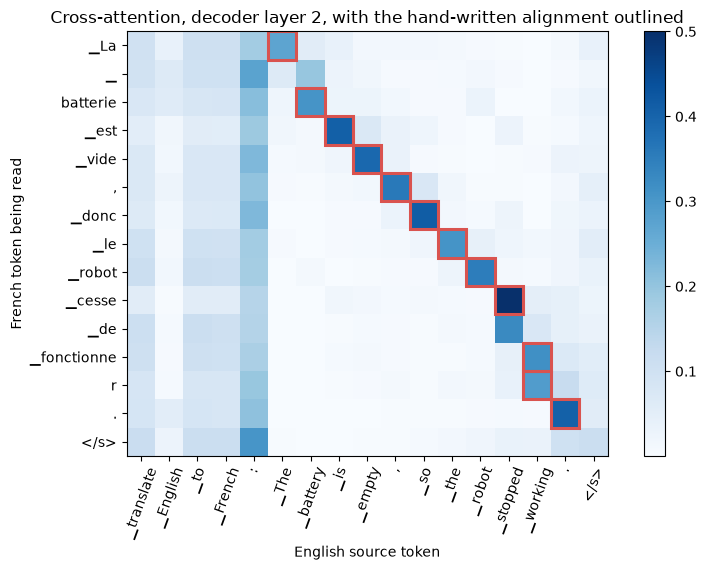

layer 2: 12 of 12 tokens have their strongest weight inside the outline


In [11]:
# Figure 4.5: the hand-written alignment drawn on the cross-attention map of decoder layer 2
fig, ax = plt.subplots(figsize=(8.5, 5.8)); im = ax.imshow(cross[1][1:], cmap="Blues")
for r, s in reference.items(): ax.add_patch(plt.Rectangle((s - 0.5, r - 1 - 0.5), 1, 1, fill=False, edgecolor="#D9534F", lw=2.2))
ax.set_xticks(range(len(src_tok)), src_tok, rotation=70); ax.set_yticks(range(len(dec_tok) - 1), dec_tok[1:])
ax.set(xlabel="English source token", ylabel="French token being read", title="Cross-attention, decoder layer 2, with the hand-written alignment outlined"); plt.colorbar(im); plt.tight_layout(); plt.show()
print(f"layer 2: {sum(int(cross[1, r].argmax()) == s for r, s in reference.items())} of {len(reference)} tokens have their strongest weight inside the outline")

*Figure 4.5 — The hand-written word alignment outlined on T5's cross-attention (decoder layer 2). Each outlined cell pairs a French token with the English token it translates; in this layer the darkest cell of each row falls inside the outline for all 12 of the 12 tokens.*

In [12]:
families = pd.DataFrame({"parameters (M)": [params(bert), params(gpt), params(t5)], "tokens each position can read": ["all", "earlier ones", "encoder: all; decoder: earlier ones + all of the source"],
                         "trained to": ["recover masked tokens", "predict the next token", "produce the target text given the source"], "one pass gives": ["a vector per token", "a distribution for every next token", "a distribution for the next target token"]},
                        index=["BERT-base (encoder)", "GPT-2 small (decoder)", "T5-small (encoder-decoder)"]); families["parameters (M)"] = families["parameters (M)"].round(0).astype(int)
display(families)

,parameters (M),tokens each position can read,trained to,one pass gives
BERT-base (encoder),110,all,recover masked tokens,a vector per token
GPT-2 small (decoder),124,earlier ones,predict the next token,a distribution for every next token
T5-small (encoder-decoder),61,encoder: all; decoder: earlier ones + all of t...,produce the target text given the source,a distribution for the next target token


BERT and GPT-2 are about the same size (110M and 124M), T5-small is smaller (61M).

An encoder gives a vector for every token, and is used for classification, search and embeddings. A decoder gives a next-token distribution at every position, and is used for generation. An encoder–decoder reads a source and generates the output. In 2018 these were separate families. Since GPT-3, decoder-only models have been used for nearly everything, including tasks that used to need an encoder, by putting the source in the prompt. Sessions 6 to 8 build on decoders.

## What to take away

- The three layouts differ in the mask. In GPT-2 the share of attention on later tokens is 0 in every layer. In BERT it is 0.59 on average. T5 uses both and adds cross-attention from the decoder to the source.
- The objective decides what the layout is for. BERT with the second half of the sentence put 0.419 on `dead`, and without it the top word changed to `charged` at 0.055. A decoder needs one pass per candidate to use later words.
- BERT's masking recipe is a training task, and we measured it: 70.4% recovered for `[MASK]`, 54.9% for random words, 99.3% for unchanged ones.
- In T5-small, one decoder layer (layer 2) reproduced our hand-written word alignment for all 12 tokens, and layers 4 to 6 did not. Attention in middle layers of all three models collapses onto a single token, so a heatmap needs checking before it is trusted.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## Objectives

BERT's loss is cross-entropy at the chosen positions only: with $\mathcal{M}$ the set of chosen positions,

$$
\mathcal{L}_{\text{MLM}}=-\sum_{t\in\mathcal{M}}\log p_\theta(x_t\mid \tilde{x}),
$$

where $\tilde{x}$ is the corrupted text. A decoder's loss $-\sum_t\log p_\theta(x_t\mid x_{<t})$ covers every position. A masked model therefore learns from about 15% of its tokens per pass and a decoder from all of them, which is one commonly given reason for decoder pre-training being more efficient per token. We did not measure this here.

T5 was pre-trained with **span corruption**: spans of the input are replaced by sentinel tokens, and the decoder writes out the missing spans. The released `t5-small` checkpoint was also trained on a mixture of supervised tasks, including translation, which is why it can follow our instruction.

## Cross-attention

In cross-attention the queries come from the decoder and the keys and values from the encoder's final output:

$$
Q=H_{\text{dec}}W^Q,\qquad K=H_{\text{enc}}W^K,\qquad V=H_{\text{enc}}W^V .
$$

The weight matrix has one row per decoder position and one column per source position, and it is not masked. In our cell each row belongs to the token the decoder has just read, which is why the row for *vide* is the one that points at *empty*.

## Other layouts

A **prefix language model** lets the first part of a sequence (the prompt) attend in both directions and the rest causally. Some models use a mask like this. Encoder-only models are still the standard choice for retrieval and classification embeddings, because one pass gives a vector per token and there is no need to generate.

## Why decoders won

The usual account is that a single next-token objective applies to any text without labels, scales smoothly, and turns every task into text continuation, so one model covers many tasks through the prompt. This session measured what the layouts do, and it does not test that account.